# HW4 — Weekly stock selection with a quarterly-refitted Ridge model

**Vasileios Dimitropoulos** · UCB MFE Python pre-program · HW4

This notebook runs the whole experiment end to end on the full `equities_top2000.duckdb` database:

1. load data and build causal features / 90-day labels (`hw4lib/data.py`, `hw4lib/features.py`);
2. **development (2010–2015)**: compare models with chronological walk-forward validation, then choose the portfolio size and the refit schedule with development-only backtests;
3. freeze every choice, then run the **final test (Apr 1 2016 – Sep 30 2026) once** with my own backtester (`hw4lib/backtester.py`);
4. compare with $1,000,000 in `^SP500TR`, audit the accounting and timing, and document data gaps.

Run instructions are in `README.md` (≈3 minutes end to end). Small result tables and the chart are written to `results/`; large files (feature panel, fills, NAV) go to `outputs/` which is git-ignored.

In [1]:
import sys, json, warnings
warnings.filterwarnings("ignore", category=UserWarning)  # quarantine counts are printed explicitly below
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.insert(0, str(Path.cwd()))
from hw4lib.pipeline import load_everything, CONFIG, RESULTS, OUTPUTS
from hw4lib.features import NUMERIC_FEATURES, SUSPECT_JUMP
from hw4lib.model import (GBMModel, RidgeRanker, MomentumScore, walk_forward,
                          prediction_metrics, training_rows)
from hw4lib.strategy import WeeklyTopN
from hw4lib.backtester import Backtester
from hw4lib.analytics import (performance, comparison_table, benchmark_nav,
                              audit_cash, audit_nav, audit_timing)

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
RESULTS.mkdir(exist_ok=True); OUTPUTS.mkdir(exist_ok=True)

## 1. Data, features and labels

* **Universe.** For a signal at the close of day *t*, the purchase is at the next session's close, so a stock is a candidate only if it is in `universe_membership` for the **quarter of the entry session** and that list's `selection_date ≤ t` (same rule as the lecture helper). Stocks that later leave the universe are never removed from history; held lots are kept to maturity.
* **Extra screens (information known at *t*):** a quote at *t*, 63 complete trailing daily returns, raw close ≥ \$5, 63-session average raw dollar volume ≥ \$2M, and **no ×3 (or ÷3) jump between consecutive quotes in the last 252 sessions** (a data-quality screen, see below).
* **Schedule.** Signals on the **first market session of each week**; purchases fill at the next session's close. 90 calendar days = 12 weeks + 6 days, so a Tuesday purchase matures on a Monday and its proceeds are ready for the next Tuesday purchase.
* **Label.** Adjusted-close return from the entry close to the first quoted close on/after entry + 90 calendar days (≤ 5 sessions late, otherwise missing). Adjusted prices already include dividends, so dividends are never added again.

In [2]:
mkt, panel = load_everything()          # builds outputs/panel.parquet on the first run (~30 s)
print("Quarantined rows:", mkt.audit)
print(f"Prices: {mkt.adj.shape[0]:,} sessions x {mkt.adj.shape[1]:,} symbols "
      f"({mkt.calendar[0].date()} -> {mkt.calendar[-1].date()})")
print(f"Panel: {len(panel):,} eligible (signal date, stock) rows, {panel.date.nunique()} weekly signal dates")
summary = panel.groupby(panel.date.dt.year).agg(rows=("symbol", "size"), stocks_per_week=("symbol", lambda s: len(s)),
                                                 labelled=("target", lambda x: x.notna().mean()))
summary["stocks_per_week"] = (summary.rows / panel.groupby(panel.date.dt.year).date.nunique()).round(0)
display(summary.T)

load database: 15.1s


Quarantined rows: {'price_rows_in_window': 12566103, 'off_calendar_rows_quarantined': 27, 'invalid_adj_rows_quarantined': 0}
Prices: 4,716 sessions x 3,849 symbols (2008-01-02 -> 2026-09-30)
Panel: 1,465,719 eligible (signal date, stock) rows, 875 weekly signal dates


date,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
rows,"60,481.0000","64,332.0000","66,389.0000","72,359.0000","81,287.0000","86,859.0000","89,884.0000","92,638.0000","97,657.0000","95,514.0000","95,738.0000","97,499.0000","96,810.0000","96,783.0000","99,134.0000","98,017.0000","74,338.0000"
stocks_per_week,"1,163.0000","1,237.0000","1,253.0000","1,392.0000","1,563.0000","1,670.0000","1,696.0000","1,782.0000","1,843.0000","1,837.0000","1,841.0000","1,875.0000","1,862.0000","1,861.0000","1,870.0000","1,885.0000","1,906.0000"
labelled,0.9999,1.0000,0.9998,0.9998,0.9999,0.9999,0.9986,0.9982,0.9996,0.9997,0.9997,0.9937,0.9876,0.9896,0.9892,0.9868,0.6557


**Data-quality finding.** Some tickers contain broken price series: AAM jumps 25,700 → 0.19 → 26,000 on consecutive days; LCI's adjusted close goes 29 → 493 in one week in Dec 2013 and stays there (a broken split adjustment). One such quote inside a holding would multiply NAV by orders of magnitude. Two safeguards, both using only past information:

1. the entry screen above (no ×3 jump in the last year), and
2. in the backtester, a quote more than ×3 / ÷3 away from the last accepted mark is not traded on or used for marking. A **fall** is accepted after it persists 5 sessions (a real crash is booked as a loss); a **rise** is never accepted — so a data error can never *increase* NAV.

In [3]:
ret = np.log(mkt.adj.ffill()).diff().where(mkt.adj.notna())
jumps = (ret.abs() > np.log(SUSPECT_JUMP)).sum()
print(f"Symbols with at least one x{SUSPECT_JUMP:g} quote-to-quote jump since 2008: {(jumps > 0).sum()} "
      f"(total jumps: {int(jumps.sum())})")
display(pd.DataFrame({"LCI adj_close": mkt.adj.loc["2013-12-09":"2013-12-20", "LCI"],
                      "LCI raw close": mkt.close.loc["2013-12-09":"2013-12-20", "LCI"]}).T)

Symbols with at least one x3 quote-to-quote jump since 2008: 443 (total jumps: 2232)


date,2013-12-09,2013-12-10,2013-12-11,2013-12-12,2013-12-13,2013-12-16,2013-12-17,2013-12-18,2013-12-19,2013-12-20
LCI adj_close,31.2000,30.8200,29.0900,28.0900,474.0800,472.1600,475.2000,478.5600,492.9600,530.8800
LCI raw close,31.2000,30.8200,29.0900,28.0900,118.5200,118.0400,118.8000,119.6400,123.2400,132.7200


**Audit of implausible universe-ranking inputs** (the data guide asks for this). The quarterly ranking uses *selection close × latest known shares*; split/share-class mismatches produce impossible capitalizations. I flag membership rows with a close above \$1M, more than 30B shares, or a capitalization proxy above \$6T, and check whether my strategy ever traded those symbols. These rows are **not** corrected (no source supports a correction). Their only effect on my features is through the valuation/size ratios, and those enter the model as same-date percentile ranks, so an absurd value only moves that stock to the end of the ranking.

In [4]:
import duckdb
from hw4lib.data import FULL_DB
with duckdb.connect(str(FULL_DB), read_only=True) as con:
    mem = con.execute("SELECT quarter_start, symbol, selection_close, selection_shares, market_cap_proxy, "
                      "universe_rank FROM universe_membership").fetchdf()
rules = pd.DataFrame({"close > $1M": mem.selection_close > 1e6, "shares > 30B": mem.selection_shares > 3e10,
                      "cap proxy > $6T": mem.market_cap_proxy > 6e12})
flagged = mem[rules.any(axis=1)].assign(rule=rules[rules.any(axis=1)].apply(lambda r: ", ".join(r.index[r]), axis=1))
ranking_audit = flagged.groupby("symbol").agg(quarters=("quarter_start", "size"), first=("quarter_start", "min"),
                                              last=("quarter_start", "max"), max_cap_proxy=("market_cap_proxy", "max"),
                                              best_rank=("universe_rank", "min"), rule=("rule", "first"))
ranking_audit.sort_values("max_cap_proxy", ascending=False).to_csv(RESULTS / "ranking_input_audit.csv")
print(f"Flagged membership rows: {len(flagged)} ({rules.sum().to_dict()}), {ranking_audit.shape[0]} symbols")
display(ranking_audit.sort_values("max_cap_proxy", ascending=False).head(10)
        .style.format({"max_cap_proxy": "${:,.3g}"}))

Flagged membership rows: 402 ({'close > $1M': 277, 'shares > 30B': 98, 'cap proxy > $6T': 33}), 27 symbols


,quarters,first,last,max_cap_proxy,best_rank,rule
symbol,,,,,,
BRK-A,17,2020-07-01 00:00:00,2024-07-01 00:00:00,$1.37e+15,1,cap proxy > $6T
TMBR,6,2015-10-01 00:00:00,2018-04-01 00:00:00,$4e+13,1,cap proxy > $6T
IVR,1,2016-04-01 00:00:00,2016-04-01 00:00:00,$1.5e+13,2,"shares > 30B, cap proxy > $6T"
RCA,18,2014-10-01 00:00:00,2022-04-01 00:00:00,$1.2e+13,1,"shares > 30B, cap proxy > $6T"
KDNY,17,2015-10-01 00:00:00,2019-10-01 00:00:00,$1.01e+13,1,shares > 30B
AVGOP,7,2021-01-01 00:00:00,2022-07-01 00:00:00,$8.95e+12,2,cap proxy > $6T
INPX,17,2014-07-01 00:00:00,2018-10-01 00:00:00,$3.69e+12,1,close > $1M
SEEL,65,2000-01-01 00:00:00,2016-01-01 00:00:00,$2.74e+12,1,close > $1M
APDN,71,2000-01-01 00:00:00,2017-10-01 00:00:00,$2.27e+12,1,close > $1M


### Features (28 numeric + sector)

All are computed from information available at the signal close:

| Group | Features |
|---|---|
| Price (adjusted closes, no filling) | momentum 5/21/63/126 sessions, 12-1 month momentum, volatility 63/252, max daily return 21, drawdown from 252-day high, 252-day beta to `^SP500TR`, log 63-day dollar volume (raw close × raw volume) |
| Fundamentals (latest quarterly filing, usable from filing date + 1 day; blank if fiscal end > 550 days old) | TTM gross profit/assets, ROA, ROE, operating margin, accruals, FCF/assets, debt/assets, cash/assets, YoY asset growth, YoY sales growth, TTM net buyback/assets, days since filing |
| Valuation (point-in-time shares from the quarterly selection × signal-date raw close) | log market cap, earnings yield, book/price, sales/price, FCF yield |
| Category | sector (snapshot label — a known limitation) |

**Preprocessing:** each numeric feature is replaced by its **percentile rank among the eligible stocks on the same date**. This is purely same-date (nothing is learned from other periods, so it cannot leak), neutralises unit/currency problems in the vendor fundamentals, and makes 2010 and 2025 comparable. Missing values stay missing (Ridge maps them to the median 0.5 plus a missing-indicator).

**Target:** the model predicts each stock's 90-day return *relative to the other eligible stocks that week* — expressed as its same-date percentile rank minus 0.5. A top-N strategy only needs the ordering, and the rank target is robust to the remaining bad prices (e.g. LCI's "+2,700%").

In [5]:
dev_mask = panel.date.le(CONFIG["dev_end"])
cov = panel.loc[dev_mask, NUMERIC_FEATURES].notna().mean().rename("non-missing share (dev)")
display(cov.to_frame().T)

,mom_5,mom_21,mom_63,mom_126,mom_252_21,vol_63,vol_252,max_ret_21,drawdown_252,beta_252,log_dollar_volume,gp_to_assets,roa,roe,op_margin,accruals,fcf_to_assets,debt_to_assets,cash_to_assets,asset_growth,sales_growth,net_buyback,log_mcap,earnings_yield,book_to_price,sales_to_price,fcf_yield,filing_age_days
non-missing share (dev),1.0000,1.0000,1.0000,0.9920,0.9745,1.0000,0.9818,1.0000,0.9819,0.9818,1.0000,0.9945,0.9946,0.9641,0.9885,0.9858,0.9858,0.9984,0.9984,0.9046,0.9020,0.9858,1.0000,0.9958,0.9985,0.9958,0.9865,1.0000


## 2. Development: model validation (2010–2015 only)

**Chronological validation.** Four yearly walk-forward folds: for validation year *Y* ∈ {2012, 2013, 2014, 2015}, the model is fitted at the first signal of *Y* using signals from 2010 onwards **whose 90-day outcome had already ended before the fit date** (`label_end < fit_date`), then scores every week of *Y*. No row from 2016 or later is used anywhere in this section (2015-fold labels finish in the Jan–Mar 2016 buffer).

**Metrics.** Mean weekly Spearman rank IC between the score and the realised 90-day return; and — what a long-only top-N portfolio actually earns — the average return of the top-20 picks (returns capped at −90%/+100% so a few broken series cannot dominate) **minus the S&P 500 TR over the same entry→exit window**.

In [6]:
dev = panel.loc[dev_mask].copy()
b = mkt.benchmark
dev["bench_90d"] = b.reindex(dev.label_end).to_numpy() / b.reindex(dev.entry_date).to_numpy() - 1
dev_dates = pd.DatetimeIndex(sorted(dev.date.unique()))
yearly_fits = [dev_dates[dev_dates.year == y].min() for y in (2012, 2013, 2014, 2015)]

candidates = {
    "12-1 momentum (no fit)": lambda: MomentumScore(),
    "Ridge a=10": lambda: RidgeRanker("y_rank", 10.0),
    "Ridge a=100": lambda: RidgeRanker("y_rank", 100.0),
    "Ridge a=1000": lambda: RidgeRanker("y_rank", 1000.0),
    "Ridge a=10000": lambda: RidgeRanker("y_rank", 10000.0),
    "Ridge a=1000, excess-return target": lambda: RidgeRanker("y_excess", 1000.0),
    "LightGBM regression": lambda: GBMModel("y_rank"),
    "LightGBM lambdarank (top-50)": lambda: GBMModel(objective="lambdarank", n_bins=10, top_k=50),
}

def topn_vs_sp(frame, preds, n=20):
    e = frame.merge(preds[["date", "symbol", "score"]], on=["date", "symbol"]).dropna(subset=["target"])
    e["capped"] = e.target.clip(-0.9, 1.0)
    top = e.sort_values("score", ascending=False).groupby("date").head(n)
    g = top.groupby("date").agg(r=("capped", "mean"), sp=("bench_90d", "first"))
    by_year = (g.r - g.sp).groupby(g.index.year).mean()
    return (g.r - g.sp).mean(), int((by_year > 0).sum()), by_year.min()

rows = []
for name, make in candidates.items():
    preds, _ = walk_forward(dev, make, yearly_fits, CONFIG["dev_end"])
    m = prediction_metrics(dev, preds)
    ics = {f"IC {y}": prediction_metrics(dev, preds[preds.date.dt.year == y]).mean_IC for y in (2012, 2013, 2014, 2015)}
    edge, years_up, worst = topn_vs_sp(dev, preds)
    rows.append({"model": name, "mean IC": m.mean_IC, **ics, "top-decile excess (90d)": m.top_decile_excess,
                 "top-20 minus S&P (90d)": edge, "years top-20 > S&P": years_up, "worst year": worst})
validation = pd.DataFrame(rows).set_index("model")
validation.to_csv(RESULTS / "validation_models.csv")
display(validation)

,mean IC,IC 2012,IC 2013,IC 2014,IC 2015,top-decile excess (90d),top-20 minus S&P (90d),years top-20 > S&P,worst year
model,,,,,,,,,
12-1 momentum (no fit),0.0363,0.0604,0.0404,-0.0285,0.0723,0.0112,-0.0140,2,-0.0786
Ridge a=10,0.0193,0.0409,-0.0600,0.0290,0.0666,-0.0008,0.0057,3,-0.0098
Ridge a=100,0.0188,0.0399,-0.0606,0.0289,0.0665,-0.0015,0.0051,3,-0.0081
Ridge a=1000,0.0178,0.0345,-0.0619,0.0313,0.0672,-0.0011,0.0058,2,-0.0047
Ridge a=10000,0.0116,0.0170,-0.0717,0.0338,0.0673,0.0003,0.0065,3,-0.0105
"Ridge a=1000, excess-return target",0.0135,0.0403,-0.0507,0.0142,0.0494,0.0000,0.0048,3,-0.0247
LightGBM regression,0.0066,0.0328,-0.0495,0.0064,0.0362,-0.0045,-0.0064,2,-0.0293
LightGBM lambdarank (top-50),-0.0140,0.0102,-0.0052,-0.0039,-0.0575,-0.0051,-0.0028,3,-0.0471


**Model choice: Ridge (α = 1000) on rank features with the rank target.**

* Every learned signal is weak (mean IC ≈ 0.01–0.02) and 2013 — a low-quality "junk rally" year — is negative for all of them. That is an honest property of this universe, not a bug.
* LightGBM (regression and lambdarank) was my prior favourite but it was *less* stable than Ridge: with only 2–5 years of training data the trees fit noise, and its top decile did not beat the universe. Ridge with a strong penalty is the most robust: near-best IC, top-20 picks ahead of the S&P on average, and the mildest worst year.
* 12-1 momentum alone looked best before capping returns, but that was entirely one broken series (LCI); with capped returns its top-20 picks were poor, which is also why I use the rank target.

### Development: portfolio size and refit schedule

Full backtests with my backtester on development predictions only (Jan 2012 – Dec 2015, 10 bp per side), compared with `^SP500TR` over the same dates. Selection rule fixed in advance: **highest development Sharpe ratio**.

In [7]:
sectors = mkt.universe.set_index("symbol").sector
quarterly_fits = [dev_dates[(dev_dates.year == y) & (dev_dates.quarter == q)].min()
                  for y in (2012, 2013, 2014, 2015) for q in (1, 2, 3, 4)]

def run_bt(preds, start, end, top_n, fee_bps=CONFIG["fee_bps_per_side"]):
    strat = WeeklyTopN(preds, sectors, top_n=top_n, cohort_fraction=CONFIG["cohort_fraction"],
                       name_cap=CONFIG["name_cap"], sector_cap=CONFIG["sector_cap"])
    bt = Backtester(mkt.adj, strat, initial_cash=CONFIG["initial_cash"], fee_bps=fee_bps,
                    holding_days=CONFIG["holding_days"], max_stale_sessions=CONFIG["max_stale_sessions"],
                    suspect_jump=CONFIG["suspect_jump"])
    return bt.run(start, end)

rows = []
for refit, fits in [("yearly", yearly_fits), ("quarterly", quarterly_fits)]:
    preds, _ = walk_forward(dev, lambda: RidgeRanker("y_rank", 1000.0), fits, CONFIG["dev_end"])
    start = mkt.calendar[mkt.calendar.get_loc(fits[0]) + 1]
    for n in (10, 20, 40):
        res = run_bt(preds, start, CONFIG["dev_end"], n)
        t = comparison_table(res, mkt.benchmark)
        s, bm = t.iloc[:, 0], t.iloc[:, 2]
        rows.append({"refit": refit, "top N per week": n, "final value": s.final_value, "CAGR": s.CAGR,
                     "max DD": s.max_drawdown, "Sharpe": s["Sharpe (rf=2%)"],
                     "S&P CAGR": bm.CAGR, "S&P Sharpe": bm["Sharpe (rf=2%)"],
                     "avg cash share": (res.history.cash / res.history.nav).iloc[1:].mean()})
selection = pd.DataFrame(rows)
selection.to_csv(RESULTS / "dev_strategy_selection.csv", index=False)
display(selection)
best = selection.loc[selection.Sharpe.idxmax()]
print(f"Chosen on development data: refit={best.refit}, top N={best['top N per week']}")

,refit,top N per week,final value,CAGR,max DD,Sharpe,S&P CAGR,S&P Sharpe,avg cash share
0,yearly,10,"1,811,500.9643",0.1605,-0.1257,0.9401,0.1492,0.9995,0.0499
1,yearly,20,"1,767,281.6456",0.1533,-0.1273,0.9151,0.1492,0.9995,0.0435
2,yearly,40,"1,621,642.1538",0.1287,-0.1333,0.7829,0.1492,0.9995,0.0417
3,quarterly,10,"1,981,630.0633",0.1869,-0.1340,1.0340,0.1492,0.9995,0.0496
4,quarterly,20,"1,930,767.5817",0.1792,-0.1364,1.0200,0.1492,0.9995,0.0428
5,quarterly,40,"1,757,119.2560",0.1517,-0.1355,0.8904,0.1492,0.9995,0.0414


Chosen on development data: refit=quarterly, top N=10


### Frozen configuration (decided before looking at any 2016+ result)

| Choice | Value |
|---|---|
| Model | Ridge, α = 1000, same-date rank features + missing indicators + sector dummies; target = same-date rank of the 90-day return |
| Training window | expanding, signals from 2010-01-01 with `label_end < fit date` |
| Refits | quarterly (first test fit after the 2016-03-31 close, then the first weekly signal of every quarter) |
| Trading | weekly; buy the 10 highest scores; equal fee-inclusive budgets; first 13 weeks: NAV/13 per week, then all available cash (cash + expected proceeds of lots maturing at that close) |
| Limits | long only, no leverage; ≤ 5% of NAV per stock, ≤ 30% per sector (snapshot sectors) |
| Holding | each lot sold at the close on its 90th calendar day, or the next session with an accepted quote |
| Costs / cash | 10 bp per side on every buy and sell; idle cash earns 0% |
| Missing prices | stale mark ≤ 5 sessions; > 5 sessions → "unresolved": no invented sale, capital frozen; NAV reported at last mark (upper bound) and with unresolved lots at 0 (lower bound) |

In [8]:
FINAL = dict(CONFIG, model="Ridge alpha=1000 rank target", refit="quarterly", top_n=int(best["top N per week"]))
assert FINAL["top_n"] == 10 and best.refit == "quarterly", "update the frozen-configuration table above"
(RESULTS / "experiment.json").write_text(json.dumps(FINAL, indent=2, default=str))

633

## 3. Final test: April 1 2016 – September 30 2026 (run once)

Walk-forward scoring: the first model is fitted after the 2016-03-31 close (that signal buys at the **first test close, 2016-04-01**, the same close at which the benchmark is bought). Every later quarter the model is refitted on all rows whose outcome had finished by then — this is why the buffer matters: a late-2015 signal's label ends in early 2016 and only becomes trainable after it ends.

In [9]:
test_rows = panel.loc[panel.date.ge(CONFIG["first_test_signal"])]
td = pd.DatetimeIndex(sorted(test_rows.date.unique()))
test_fits = [pd.Timestamp(CONFIG["first_test_signal"])] + [
    td[(td.year == y) & (td.quarter == q)].min()
    for y in range(2016, 2027) for q in (1, 2, 3, 4)
    if pd.Timestamp(year=y, month=3 * q - 2, day=1) >= pd.Timestamp("2016-07-01")
    and ((td.year == y) & (td.quarter == q)).any()]
preds, fit_audit = walk_forward(panel.loc[panel.date.ge(CONFIG["train_start"])], lambda: RidgeRanker("y_rank", 1000.0),
                                test_fits, CONFIG["test_end"])
preds = preds.loc[preds.date.ge(CONFIG["first_test_signal"])]
fit_audit.to_csv(RESULTS / "fit_audit.csv", index=False)
preds.to_parquet(OUTPUTS / "test_predictions.parquet")
print(f"{len(test_fits)} fits; first {test_fits[0].date()}, last {test_fits[-1].date()}; {len(preds):,} scored rows")
display(fit_audit.head(3)); display(fit_audit.tail(2))
assert (pd.to_datetime(fit_audit.last_training_label_end) < pd.to_datetime(fit_audit.first_scored_signal)).all()

42 fits; first 2016-03-31, last 2026-07-06; 1,012,104 scored rows


,fit_date,training_rows,first_training_signal,last_training_signal,last_training_label_end,first_scored_signal,last_scored_signal,scored_rows
0,2016-03-31,431651,2010-01-04,2015-12-28,2016-03-28,2016-03-31,2016-06-27,23477
1,2016-07-05,455196,2010-01-04,2016-03-31,2016-06-30,2016-07-05,2016-09-26,22099
2,2016-10-03,476916,2010-01-04,2016-06-27,2016-09-26,2016-10-03,2016-12-27,22400


,fit_date,training_rows,first_training_signal,last_training_signal,last_training_label_end,first_scored_signal,last_scored_signal,scored_rows
40,2026-04-06,1385761,2010-01-04,2025-12-29,2026-03-30,2026-04-06,2026-06-29,24788
41,2026-07-06,1410101,2010-01-04,2026-03-30,2026-06-29,2026-07-06,2026-09-28,24865


In [10]:
result = run_bt(preds, CONFIG["test_start"], CONFIG["test_end"], FINAL["top_n"])
h = result.history
bench = benchmark_nav(mkt.benchmark, h, result.initial_cash)
h["benchmark_nav"] = bench
h.to_csv(OUTPUTS / "test_nav.csv"); result.fills.to_csv(OUTPUTS / "test_fills.csv", index=False)
result.open_lots.to_csv(RESULTS / "open_lots_at_end.csv", index=False)
print(f"Sessions: {len(h) - 1} ({h.index[1].date()} -> {h.index[-1].date()}); "
      f"buys {int((result.fills.side == 'BUY').sum()):,}, sells {int((result.fills.side == 'SELL').sum()):,}, "
      f"open lots at end {len(result.open_lots)}")

Sessions: 2640 (2016-04-01 -> 2026-09-30); buys 5,489, sells 5,313, open lots at end 176


### Performance vs. $1,000,000 in `^SP500TR` at the first test close

Both portfolios start from the same \$1,000,000 initial-capital row (dated 2016-03-31, the signal close). The benchmark buys `^SP500TR` at the **2016-04-01 close**, the same close as the strategy's first purchases, and the strategy's first-day fees are therefore included in its first daily return and drawdown (lecture convention). Final values include cash and all open positions marked at the 2026-09-30 close. Sharpe uses daily simple returns and a 2% annual risk-free rate converted to a daily rate.

In [11]:
perf = comparison_table(result, mkt.benchmark, CONFIG["risk_free_for_sharpe"])
perf.to_csv(RESULTS / "performance.csv")
show = perf.T[["final_value", "total_return", "CAGR", "max_drawdown", "annualized_volatility", "Sharpe (rf=2%)"]]
display(show.style.format({"final_value": "${:,.0f}", "total_return": "{:.1%}", "CAGR": "{:.2%}",
                           "max_drawdown": "{:.1%}", "annualized_volatility": "{:.1%}", "Sharpe (rf=2%)": "{:.2f}"}))
s, lo, bm = perf.iloc[:, 0], perf.iloc[:, 1], perf.iloc[:, 2]
verdict = "BEAT" if s.final_value > bm.final_value else "DID NOT BEAT"
print(f"Strategy {verdict} the benchmark: final value ${s.final_value:,.0f} vs ${bm.final_value:,.0f} "
      f"(difference ${s.final_value - bm.final_value:+,.0f}); CAGR {s.CAGR:.2%} vs {bm.CAGR:.2%} "
      f"({(s.CAGR - bm.CAGR) * 100:+.2f} pp/yr); Sharpe {s['Sharpe (rf=2%)']:.2f} vs {bm['Sharpe (rf=2%)']:.2f}")
print(f"Lower bound (unresolved lots written off): ${lo.final_value:,.0f}, CAGR {lo.CAGR:.2%}")

,final_value,total_return,CAGR,max_drawdown,annualized_volatility,Sharpe (rf=2%)
Strategy (unresolved lots at last mark),"$2,320,392",132.0%,8.35%,-38.9%,19.8%,0.41
Strategy (unresolved lots at zero),"$1,655,393",65.5%,4.92%,-44.5%,21.7%,0.24
S&P 500 TR (^SP500TR),"$4,402,747",340.3%,15.16%,-33.8%,17.8%,0.77


Strategy DID NOT BEAT the benchmark: final value $2,320,392 vs $4,402,747 (difference $-2,082,354); CAGR 8.35% vs 15.16% (-6.82 pp/yr); Sharpe 0.41 vs 0.77
Lower bound (unresolved lots written off): $1,655,393, CAGR 4.92%


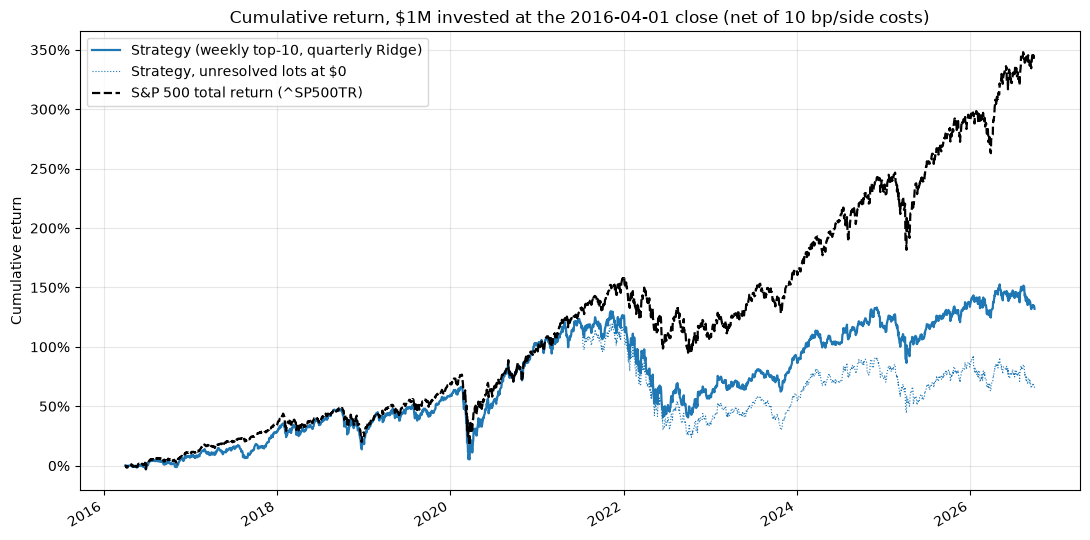

In [12]:
fig, ax = plt.subplots(figsize=(11, 5.5))
(h.nav / result.initial_cash - 1).plot(ax=ax, color="#1f77b4", lw=1.6, label="Strategy (weekly top-10, quarterly Ridge)")
(h.nav_low / result.initial_cash - 1).plot(ax=ax, color="#1f77b4", lw=0.8, ls=":", label="Strategy, unresolved lots at $0")
(h.benchmark_nav / result.initial_cash - 1).plot(ax=ax, color="black", lw=1.6, ls="--", label="S&P 500 total return (^SP500TR)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.set(title="Cumulative return, $1M invested at the 2016-04-01 close (net of 10 bp/side costs)",
       ylabel="Cumulative return", xlabel="")
ax.grid(alpha=0.3); ax.legend(loc="upper left")
fig.tight_layout(); fig.savefig(RESULTS / "cumulative_returns.png", dpi=150); plt.show()

In [13]:
yearly = pd.DataFrame({"strategy": h.nav.resample("YE").last(), "S&P 500 TR": h.benchmark_nav.resample("YE").last()})
yearly = pd.concat([h[["nav", "benchmark_nav"]].iloc[:1].set_axis(yearly.columns, axis=1), yearly]).pct_change().dropna()
yearly.index = yearly.index.year
yearly["difference"] = yearly.strategy - yearly["S&P 500 TR"]
yearly.to_csv(RESULTS / "calendar_year_returns.csv")
display(yearly.style.format("{:.1%}").set_caption("Calendar-year returns (2016 from Apr 1; 2026 to Sep 30)"))

,strategy,S&P 500 TR,difference
date,,,
2016,6.9%,9.8%,-2.9%
2017,19.6%,21.8%,-2.2%
2018,-5.2%,-4.4%,-0.9%
2019,30.7%,31.5%,-0.8%
2020,28.1%,18.4%,9.7%
2021,10.6%,28.7%,-18.1%
2022,-29.5%,-18.1%,-11.3%
2023,21.5%,26.3%,-4.8%
2024,12.5%,25.0%,-12.5%


## 4. Checking the accounting and timing

1. **Hand check** of the first purchase and its sale, recomputed from raw prices.
2. **Cash** rebuilt from the fill ledger alone (initial cash + cumulative `cash_change`).
3. **NAV** rebuilt from fills × the raw quote matrix (independent of the backtester's loop).
4. **Timing**: every buy fills at the session after its signal; due date = entry + 90 calendar days; no sale before maturity; sales on the first session on/after maturity unless the quote was missing/suspect.
5. **PnL identity**: realised PnL of closed lots + (open-lot value − open-lot cost incl. entry fees) = final NAV − $1,000,000.

In [14]:
f = result.fills
first_buy = f[f.side == "BUY"].iloc[0]
its_sale = f[(f.side == "SELL") & (f.lot_id == first_buy.lot_id)].iloc[0]
fee = CONFIG["fee_bps_per_side"] / 1e4
p_in = mkt.adj.loc[first_buy.date, first_buy.symbol]; p_out = mkt.adj.loc[its_sale.date, first_buy.symbol]
budget = -first_buy.cash_change
units = budget / (p_in * (1 + fee))
by_hand = pd.Series({
    "symbol": first_buy.symbol, "signal date": first_buy.signal_date.date(), "fill date": first_buy.date.date(),
    "entry adj close (raw data)": p_in, "budget incl. fee": budget, "units = budget/(p*(1+fee))": units,
    "entry fee = units*p*fee": units * p_in * fee, "due = entry + 90 days": (first_buy.date + pd.Timedelta(days=90)).date(),
    "sale date": its_sale.date.date(), "exit adj close (raw data)": p_out,
    "sale cash = units*p*(1-fee)": units * p_out * (1 - fee),
    "PnL = sale cash - budget": units * p_out * (1 - fee) - budget})
display(by_hand.to_frame("hand calculation"))
assert np.isclose(units, first_buy.units) and np.isclose(units * p_in * fee, first_buy.fee)
assert np.isclose(units * p_out * (1 - fee), its_sale.cash_change)
assert np.isclose(units * p_out * (1 - fee) - budget, its_sale.realized_pnl)
assert its_sale.date == mkt.calendar[mkt.calendar.searchsorted(first_buy.date + pd.Timedelta(days=90))]
print("Hand check matches the backtester's ledger.")

,hand calculation
symbol,WBA
signal date,2016-03-31
fill date,2016-04-01
entry adj close (raw data),62.2000
budget incl. fee,"7,692.3077"
units = budget/(p*(1+fee)),123.5470
entry fee = units*p*fee,7.6846
due = entry + 90 days,2016-06-30
sale date,2016-06-30
exit adj close (raw data),60.0100


Hand check matches the backtester's ledger.


In [15]:
nav_gap = audit_nav(result, mkt.adj)
ol = result.open_lots
closed_pnl = f.loc[f.side == "SELL", "realized_pnl"].sum()
open_unrealised = (ol.market_value - ol.units * ol.entry_price - ol.entry_fee).sum() if len(ol) else 0.0
checks = pd.concat([audit_timing(result, mkt.calendar), pd.Series({
    "max |cash - cash rebuilt from fills| ($)": audit_cash(result),
    "days where independent NAV rebuild differs by > $1": int((nav_gap.abs() > 1).sum()),
    "max |NAV - independent rebuild| ($)": float(nav_gap.abs().max()),
    "final NAV = cash + open lots at marks": bool(np.isclose(h.nav.iloc[-1], h.cash.iloc[-1] + (ol.market_value.sum() if len(ol) else 0))),
    "realised + unrealised PnL = NAV - initial": bool(np.isclose(closed_pnl + open_unrealised, h.nav.iloc[-1] - result.initial_cash)),
    "total fees paid ($)": f.fee.sum(),
    "orders rejected (missing quote)": int((result.diagnostics.event == "rejected_missing_quote").sum()),
    "orders rejected (suspect quote)": int((result.diagnostics.event == "rejected_suspect_quote").sum()),
    "average cash share of NAV (after first 13 weeks)": float((h.cash / h.nav).iloc[66:].mean()),
})])
checks.astype(str).to_frame("value").to_csv(RESULTS / "accounting_checks.csv")
display(checks.to_frame("value"))
if (nav_gap.abs() > 1).any():
    print("Days where the naive rebuild differs (it uses every raw quote, including the suspect ones the backtester ignores):")
    display(nav_gap[nav_gap.abs() > 1].describe())

,value
buys,5489
sells,5313
buys filled at the session after their signal,True
due date = entry + 90 calendar days,True
no sale before maturity,True
sales on first session on/after maturity,5313
sales delayed (missing/suspect quote at maturity),0
each lot sold at most once,True
min cash,0.0000
max |cash - cash rebuilt from fills| ($),0.0000


Days where the naive rebuild differs (it uses every raw quote, including the suspect ones the backtester ignores):


count         4.0000
mean    -72,921.7089
std         608.4873
min     -73,308.1103
25%     -73,220.1221
50%     -73,182.6871
75%     -72,884.2739
max     -72,013.3511
dtype: float64

### Data gaps encountered by the strategy

In [16]:
d = result.diagnostics
events = d.event.str.replace(r" x[0-9.]+$", "", regex=True).value_counts().rename("count")
display(events.to_frame())
unresolved = ol[ol.unresolved] if len(ol) else ol
print(f"Open lots at the end: {len(ol)}; of which unresolved (no accepted quote for > 5 sessions): {len(unresolved)}, "
      f"value at last mark ${unresolved.market_value.sum() if len(unresolved) else 0:,.0f} "
      f"({(unresolved.market_value.sum() if len(unresolved) else 0) / h.nav.iloc[-1]:.2%} of final NAV)")
if len(unresolved):
    display(unresolved[["symbol", "entry_date", "due_date", "entry_price", "last_mark", "last_quote_date", "market_value"]])
deferred = d[d.event == "exit_deferred"].merge(d[d.event == "deferred_exit_filled"][["lot_id", "date"]],
                                               on="lot_id", how="left", suffixes=("", "_filled"))
deferred.to_csv(RESULTS / "deferred_exits.csv", index=False)
traded_flagged = sorted(set(ranking_audit.index) & set(f.symbol))
print(f"Symbols with implausible ranking inputs that the strategy traded: {traded_flagged or 'none'}")
for sym in traded_flagged:
    tr = f[f.symbol == sym]
    print(f"  {sym}: {int((tr.side == 'BUY').sum())} buys, realised PnL ${tr.realized_pnl.sum():,.0f}; "
          f"flag: {ranking_audit.loc[sym, 'rule']} in {ranking_audit.loc[sym, 'quarters']} quarter(s) "
          f"({ranking_audit.loc[sym, 'first'].date()} to {ranking_audit.loc[sym, 'last'].date()})")
print(f"Exits deferred because the maturity-day quote was missing/suspect: {len(deferred)} "
      f"(later filled: {deferred.date_filled.notna().sum()})")
display(deferred.head(10))

,count
event,
unresolved_mark,7726
stale_mark,69
exit_deferred,46
orders_scaled_to_cash,4
suspect_drop_ignored,4
rejected_missing_quote,1
suspect_drop_confirmed,1


Open lots at the end: 176; of which unresolved (no accepted quote for > 5 sessions): 46, value at last mark $665,000 (28.66% of final NAV)


,symbol,entry_date,due_date,entry_price,last_mark,last_quote_date,market_value
0,WPF,2021-05-04,2021-08-02,10.1100,9.7500,2021-07-02,"13,390.9753"
1,WPF,2021-05-25,2021-08-23,10.5000,9.7500,2021-07-02,"16,833.4792"
2,WPF,2021-06-02,2021-08-31,10.3700,9.7500,2021-07-02,"18,102.7433"
3,WPF,2021-06-08,2021-09-06,10.5100,9.7500,2021-07-02,"21,333.9211"
4,WPF,2021-06-22,2021-09-20,10.0000,9.7500,2021-07-02,"23,491.0383"
5,WPF,2021-06-29,2021-09-27,9.9400,9.7500,2021-07-02,"11,238.7220"
6,CCMP,2022-04-12,2022-07-11,176.0100,173.6900,2022-07-05,"17,297.8567"
7,CCMP,2022-04-26,2022-07-25,178.4300,173.6900,2022-07-05,"18,476.1284"
8,CCMP,2022-05-03,2022-08-01,181.2200,173.6900,2022-07-05,"10,624.0411"
9,CHNG,2022-08-16,2022-11-14,24.8100,27.4900,2022-09-30,"12,546.1243"


Symbols with implausible ranking inputs that the strategy traded: ['SIX']
  SIX: 7 buys, realised PnL $-5,378; flag: shares > 30B in 1 quarter(s) (2010-10-01 to 2010-10-01)
Exits deferred because the maturity-day quote was missing/suspect: 46 (later filled: 0)


,date,symbol,event,lot_id,date_filled
0,2021-08-02,WPF,exit_deferred,"2,667.0000",NaT
1,2021-08-23,WPF,exit_deferred,"2,692.0000",NaT
2,2021-08-31,WPF,exit_deferred,"2,703.0000",NaT
3,2021-09-07,WPF,exit_deferred,"2,715.0000",NaT
4,2021-09-20,WPF,exit_deferred,"2,731.0000",NaT
5,2021-09-27,WPF,exit_deferred,"2,748.0000",NaT
6,2022-07-11,CCMP,exit_deferred,"3,152.0000",NaT
7,2022-07-25,CCMP,exit_deferred,"3,174.0000",NaT
8,2022-08-01,CCMP,exit_deferred,"3,184.0000",NaT
9,2022-11-14,CHNG,exit_deferred,"3,333.0000",NaT


## 5. Robustness and diagnostics

* **Transaction costs:** the same predictions at 0, 10 (base case) and 25 bp per side.
* **Baseline:** the same backtester with 12-1 momentum scores instead of the model.
* **Forecast quality in the test period:** rank IC on test signals whose outcome is known (weekly 90-day outcomes overlap, so the t-stat is optimistic).
* **Risk:** beta and correlation of daily strategy returns with the S&P 500 TR; average sector weights.

In [17]:
rows = []
for bps in (0, 10, 25):
    r = result if bps == CONFIG["fee_bps_per_side"] else run_bt(preds, CONFIG["test_start"], CONFIG["test_end"], FINAL["top_n"], bps)
    p = comparison_table(r, mkt.benchmark).iloc[:, 0]
    rows.append({"variant": f"Ridge top-10, {bps} bp/side", "final value": p.final_value, "CAGR": p.CAGR,
                 "max DD": p.max_drawdown, "Sharpe": p["Sharpe (rf=2%)"], "fees paid": r.fills.fee.sum()})
mom = panel.loc[panel.date.ge(CONFIG["first_test_signal"]), ["date", "symbol", "r_mom_252_21"]].dropna()
r = run_bt(mom.rename(columns={"r_mom_252_21": "score"}), CONFIG["test_start"], CONFIG["test_end"], FINAL["top_n"])
p = comparison_table(r, mkt.benchmark).iloc[:, 0]
rows.append({"variant": "12-1 momentum top-10, 10 bp/side (baseline)", "final value": p.final_value, "CAGR": p.CAGR,
             "max DD": p.max_drawdown, "Sharpe": p["Sharpe (rf=2%)"], "fees paid": r.fills.fee.sum()})
lo_m = comparison_table(r, mkt.benchmark).iloc[:, 1]
rows.append({"variant": "  ...momentum, unresolved lots at $0 (lower bound)", "final value": lo_m.final_value, "CAGR": lo_m.CAGR,
             "max DD": lo_m.max_drawdown, "Sharpe": lo_m["Sharpe (rf=2%)"], "fees paid": r.fills.fee.sum()})
# Accounting sensitivity (not the base case): unresolved lots assumed to pay their last mark at maturity.
r = Backtester(mkt.adj, WeeklyTopN(preds, sectors, top_n=FINAL["top_n"]), fee_bps=CONFIG["fee_bps_per_side"],
               unresolved_exit="last_mark").run(CONFIG["test_start"], CONFIG["test_end"])
p = comparison_table(r, mkt.benchmark).iloc[:, 0]
rows.append({"variant": "Ridge top-10, unresolved lots paid at last mark (sensitivity)", "final value": p.final_value,
             "CAGR": p.CAGR, "max DD": p.max_drawdown, "Sharpe": p["Sharpe (rf=2%)"], "fees paid": r.fills.fee.sum()})
rows.append({"variant": "S&P 500 TR", "final value": bm.final_value, "CAGR": bm.CAGR, "max DD": bm.max_drawdown,
             "Sharpe": bm["Sharpe (rf=2%)"], "fees paid": 0.0})
robust = pd.DataFrame(rows).set_index("variant")
robust.to_csv(RESULTS / "robustness.csv")
display(robust)

,final value,CAGR,max DD,Sharpe,fees paid
variant,,,,,
"Ridge top-10, 0 bp/side","2,578,188.8259",0.0944,-0.3907,0.4566,0.0000
"Ridge top-10, 10 bp/side","2,320,392.2998",0.0835,-0.3887,0.4057,"127,930.9833"
"Ridge top-10, 25 bp/side","2,077,123.1483",0.0721,-0.3940,0.3533,"297,004.9350"
"12-1 momentum top-10, 10 bp/side (baseline)","7,414,258.1129",0.2102,-0.4953,0.6613,"200,148.0860"
"...momentum, unresolved lots at $0 (lower bound)","4,426,239.3212",0.1522,-0.5185,0.5000,"200,148.0860"
"Ridge top-10, unresolved lots paid at last mark (sensitivity)","2,536,071.5719",0.0927,-0.3675,0.4386,"146,522.0066"
S&P 500 TR,"4,402,746.7763",0.1516,-0.3379,0.7725,0.0000


In [18]:
tm = prediction_metrics(panel, preds)
by_year = pd.Series({y: prediction_metrics(panel, preds[preds.date.dt.year == y]).mean_IC
                     for y in sorted(preds.date.dt.year.unique())}, name="mean weekly rank IC")
tm.to_frame("test period").to_csv(RESULTS / "test_prediction_metrics.csv")
display(tm.to_frame("test period (labelled signals)").T); display(by_year.to_frame().T)

rs, rb = h.nav.pct_change().iloc[2:], h.benchmark_nav.pct_change().iloc[2:]
beta = np.cov(rs, rb)[0, 1] / rb.var()
print(f"Daily beta to S&P 500 TR: {beta:.2f}; correlation {rs.corr(rb):.2f}; "
      f"tracking error {(rs - rb).std() * np.sqrt(252):.1%}/yr")
buys = f[f.side == "BUY"].assign(sector=lambda x: x.symbol.map(sectors))
display((buys.groupby("sector").notional.sum() / buys.notional.sum()).sort_values(ascending=False)
        .rename("share of purchases").to_frame().T)

,dates,mean_IC,IC_t,IC_hit_rate,top_decile_excess,bottom_decile_excess
test period (labelled signals),536.0000,0.0249,5.2827,0.6138,0.0044,-0.0025


,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
mean weekly rank IC,-0.0524,0.0639,0.0163,0.1251,-0.0662,0.0344,-0.0007,0.0802,0.0401,-0.0194,0.0443


Daily beta to S&P 500 TR: 0.98; correlation 0.88; tracking error 9.2%/yr


sector,Technology,Financial Services,Healthcare,Industrials,Consumer Cyclical,Real Estate,Communication Services,Consumer Defensive,Utilities,Basic Materials,Energy
share of purchases,0.3000,0.1856,0.1497,0.1466,0.1260,0.0385,0.0216,0.0181,0.0088,0.0050,0.0002


### The forecast in return units (calibration)

The model outputs a *relative* 90-day return forecast (a same-date rank). To read it as a return prediction, every test signal date's eligible stocks are split into deciles of the score, and I report the realized 90-day return of each decile (capped at −90%/+100%; outcome must be known) next to the S&P 500 over the same windows. A useful forecast should rise from decile 1 to decile 10.

In [19]:
cal = panel[["date", "symbol", "target", "entry_date", "label_end"]].merge(preds[["date", "symbol", "score"]], on=["date", "symbol"])
cal = cal.dropna(subset=["target"])
cal["decile"] = cal.groupby("date").score.transform(lambda s: pd.qcut(s.rank(method="first"), 10, labels=False) + 1)
cal["capped"] = cal.target.clip(-0.9, 1.0)
cal["sp_90d"] = mkt.benchmark.reindex(cal.label_end).to_numpy() / mkt.benchmark.reindex(cal.entry_date).to_numpy() - 1
calibration = cal.groupby("decile").agg(mean_90d_return=("capped", "mean"), median_90d_return=("target", "median"),
                                        hit_rate_vs_SP=("capped", lambda x: (x > cal.loc[x.index, "sp_90d"]).mean()),
                                        rows=("target", "size"))
calibration["S&P_90d_same_windows"] = cal.sp_90d.mean()
calibration.to_csv(RESULTS / "test_calibration_by_decile.csv")
display(calibration.style.format({"mean_90d_return": "{:.2%}", "median_90d_return": "{:.2%}", "hit_rate_vs_SP": "{:.1%}",
                                  "S&P_90d_same_windows": "{:.2%}", "rows": "{:,.0f}"}))
print(f"Top minus bottom decile: {calibration.mean_90d_return.iloc[-1] - calibration.mean_90d_return.iloc[0]:+.2%} per 90 days; "
      f"Spearman(decile, mean return) = {calibration.mean_90d_return.reset_index().corr(method='spearman').iloc[0, 1]:.2f}")

,mean_90d_return,median_90d_return,hit_rate_vs_SP,rows,S&P_90d_same_windows
decile,,,,,
1,2.22%,0.50%,43.4%,"98,353",3.76%
2,3.31%,2.16%,46.1%,"98,062",3.76%
3,3.15%,2.34%,45.9%,"98,025",3.76%
4,2.85%,2.22%,45.2%,"98,056",3.76%
5,2.70%,2.16%,44.7%,"98,139",3.76%
6,2.64%,2.23%,44.6%,"97,964",3.76%
7,2.67%,2.36%,44.9%,"98,008",3.76%
8,2.79%,2.43%,45.3%,"98,073",3.76%
9,2.89%,2.52%,45.5%,"98,014",3.76%


Top minus bottom decile: +1.17% per 90 days; Spearman(decile, mean return) = 0.25


## 6. Post-test revision (disclosed — this result is **not** out-of-sample)

The pre-registered result above is the official answer to the assignment. After seeing it, I diagnosed two problems and made **one** revision, documented here so the reader can discount it appropriately:

* **Diagnosis 1 — frozen capital.** Many unresolved lots are cash-acquisition targets (WPF, CCMP, CHNG, BECN, SQSP, …). After a deal is announced the price is pinned near the offer, so these stocks look calm and tend to beat the cross-section — exactly what the model learned to like. When the deal closes the quote series simply stops, and under my (correct) no-invented-fill policy that capital is frozen until the end.
* **Diagnosis 2 — a gap in my development process.** I chose the model with a capped-return proxy and never ran the momentum baseline through the real backtester on 2012–2015, even though momentum did very well in the test.

**Revision procedure (development data only):** backtest Ridge, 12-1 momentum and a 50/50 rank blend, each with and without a *deal-target screen* (exclude stocks whose 21-session annualised volatility is below 8% — a pinned price; information known at the signal), and keep the same rule: highest development Sharpe. Then run the test once more.

In [20]:
dev_scores = dev.loc[dev.date.ge(quarterly_fits[0]), ["date", "symbol", "r_mom_252_21", "vol_21"]].merge(
    walk_forward(dev, lambda: RidgeRanker("y_rank", 1000.0), quarterly_fits, CONFIG["dev_end"])[0][["date", "symbol", "score"]],
    on=["date", "symbol"])
dev_scores["ridge"] = dev_scores.score
dev_scores["momentum"] = dev_scores.r_mom_252_21.fillna(0.5)
dev_scores["blend"] = dev_scores.groupby("date").ridge.rank(pct=True) + dev_scores.groupby("date").momentum.rank(pct=True)
start = mkt.calendar[mkt.calendar.get_loc(quarterly_fits[0]) + 1]
rows = []
for col in ("ridge", "momentum", "blend"):
    for screen in (False, True):
        sc = dev_scores[~(dev_scores.vol_21 < 0.08)] if screen else dev_scores
        r = run_bt(sc[["date", "symbol"]].assign(score=sc[col]), start, CONFIG["dev_end"], 10)
        t = comparison_table(r, mkt.benchmark)
        rows.append({"score": col, "deal-target screen": screen, "CAGR": t.iloc[:, 0].CAGR, "max DD": t.iloc[:, 0].max_drawdown,
                     "Sharpe": t.iloc[:, 0]["Sharpe (rf=2%)"], "lower-bound CAGR": t.iloc[:, 1].CAGR,
                     "S&P CAGR": t.iloc[:, 2].CAGR, "S&P Sharpe": t.iloc[:, 2]["Sharpe (rf=2%)"]})
revision_dev = pd.DataFrame(rows)
revision_dev.to_csv(RESULTS / "revision_dev_selection.csv", index=False)
display(revision_dev)
pick = revision_dev.loc[revision_dev.Sharpe.idxmax()]
print(f"Development rule picks: score={pick.score}, screen={pick['deal-target screen']}")
assert pick.score == "ridge" and bool(pick["deal-target screen"])

,score,deal-target screen,CAGR,max DD,Sharpe,lower-bound CAGR,S&P CAGR,S&P Sharpe
0,ridge,False,0.1869,-0.1340,1.0340,0.1869,0.1492,0.9995
1,ridge,True,0.1894,-0.1366,1.0506,0.1894,0.1492,0.9995
2,momentum,False,0.0683,-0.4202,0.3098,0.0512,0.1492,0.9995
3,momentum,True,0.0683,-0.4202,0.3098,0.0512,0.1492,0.9995
4,blend,False,0.1124,-0.2200,0.5627,0.1124,0.1492,0.9995
5,blend,True,0.1124,-0.2200,0.5627,0.1124,0.1492,0.9995


Development rule picks: score=ridge, screen=True


,final_value,CAGR,max_drawdown,annualized_volatility,Sharpe (rf=2%)
Pre-registered strategy (last mark),"$2,320,392",8.35%,-38.9%,19.8%,0.41
Pre-registered (unresolved at $0),"$1,655,393",4.92%,-44.5%,21.7%,0.24
Revised strategy (last mark),"$2,461,510",8.96%,-37.7%,20.2%,0.43
Revised strategy (unresolved at $0),"$1,960,658",6.62%,-42.0%,21.5%,0.31
S&P 500 TR (^SP500TR),"$4,402,747",15.16%,-33.8%,17.8%,0.77


Revised: unresolved open lots 31, value $500,852 (pre-registered: 46, $665,000); cash audit 2.4e-09


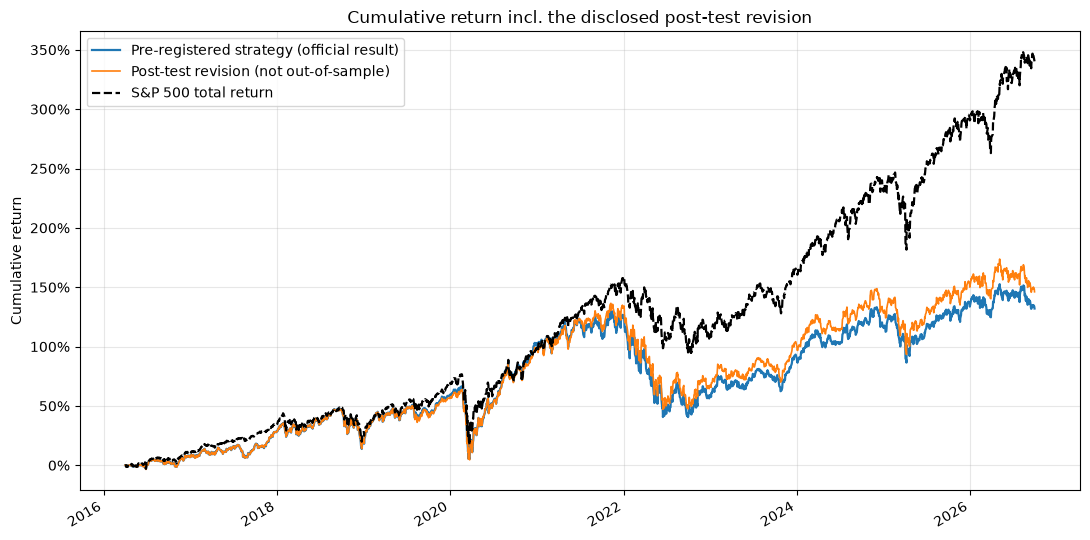

In [21]:
screened = preds.merge(panel[["date", "symbol", "vol_21"]], on=["date", "symbol"])
screened = screened[~(screened.vol_21 < 0.08)]
revised = run_bt(screened, CONFIG["test_start"], CONFIG["test_end"], FINAL["top_n"])
rev = comparison_table(revised, mkt.benchmark, CONFIG["risk_free_for_sharpe"])
rev.columns = ["Revised strategy (last mark)", "Revised strategy (unresolved at $0)", "S&P 500 TR (^SP500TR)"]
both = pd.concat([perf.iloc[:, :2].set_axis(["Pre-registered strategy (last mark)", "Pre-registered (unresolved at $0)"], axis=1), rev], axis=1)
both.to_csv(RESULTS / "performance_with_revision.csv")
display(both.T[["final_value", "CAGR", "max_drawdown", "annualized_volatility", "Sharpe (rf=2%)"]].style.format(
    {"final_value": "${:,.0f}", "CAGR": "{:.2%}", "max_drawdown": "{:.1%}", "annualized_volatility": "{:.1%}", "Sharpe (rf=2%)": "{:.2f}"}))
rol = revised.open_lots
print(f"Revised: unresolved open lots {int(rol.unresolved.sum())}, value ${rol.loc[rol.unresolved, 'market_value'].sum():,.0f} "
      f"(pre-registered: {int(ol.unresolved.sum())}, ${ol.loc[ol.unresolved, 'market_value'].sum():,.0f}); "
      f"cash audit {audit_cash(revised):.1e}")

fig, ax = plt.subplots(figsize=(11, 5.5))
(h.nav / 1e6 - 1).plot(ax=ax, color="#1f77b4", lw=1.6, label="Pre-registered strategy (official result)")
(revised.history.nav / 1e6 - 1).plot(ax=ax, color="#ff7f0e", lw=1.2, label="Post-test revision (not out-of-sample)")
(h.benchmark_nav / 1e6 - 1).plot(ax=ax, color="black", lw=1.6, ls="--", label="S&P 500 total return")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.set(title="Cumulative return incl. the disclosed post-test revision", ylabel="Cumulative return", xlabel="")
ax.grid(alpha=0.3); ax.legend(loc="upper left"); fig.tight_layout()
fig.savefig(RESULTS / "cumulative_returns_with_revision.png", dpi=150); plt.show()

## 7. Findings, risks and limitations

The written discussion (what worked, what did not, the risks taken, the main limitations, and what I would try next) is in `README.md`, next to the numbers produced above.